# ST340 Fundamentals of Machine Learning: Assessment 1

**2026--27**

<div style="text-align: right;">Released: 13:00 on Monday Week 2, 2026-10-12.</div>

<div style="text-align: right;">Deadline: 13:00 on Monday Week 4, 2026-10-26.</div>

# Instructions

* Links and instructions for using the submission portal are available on the module [Moodle page](https://moodle.warwick.ac.uk/course/view.php?id=76217). Please ensure you follow the guidelines provided.

* Any programming work should be completed in either `R` or `Python`. Your report must be created using either `R Markdown` or a `Python Jupyter Notebook`. Submit *two* files:

    1. A knitted PDF document **in A4 format**. The document must be **no more than 15 pages and could be substantially shorter**.
    2. The corresponding `R Markdown` or `Python interactive notebook` file.

* This assignment contributes 10\% to your overall module grade. In the [Assessment Handbook](https://warwick.ac.uk/fac/sci/statistics/currentstudents/assessment/assessmenthandbookpage/) it is Category C.

* This assignment is assessing your knowledge of under- and and over-fitting, as well as various approaches to model selection. The relevant parts of the lecture notes are Sections 2.4--2.5.

* Please ensure you are familiar with the University's [Guidance on the use of AI](https://warwick.ac.uk/students/academic-essentials/academic-integrity/artificial-intelligence/). For this assignment, permission to use AI is **Limited**. Permitted uses include: clarifying or improving your understanding of concepts from the module; asking for feedback on your work such as to point out errors; writing, debugging, and testing code. You may **not** use AI to write out for you any explanation or discussion which will be included with your answers; this must be written in your own words.

* If you use AI for any purpose you must include a declaration as described in the guidance linked above, which can be appended as a paragraph in your submission. You may include examples of prompts that you used, but you are not required to do so.

* AI is an amazing tool for learning and also an amazing tool to avoid learning. Your mission is to train yourself to use it responsibly.

# 1. Business data

The accompanying file `BusinessData.csv` contains data on the number of businesses in each constituency in England, as well as a variety of social and demographic measurements. The goal of this question is to construct a linear model with the number of businesses as the response. We will treat all covariates and the response as real-valued (rather than integer-valued) for simplicity.

First, load the data and restrict it to the subset of covariates that will be the focus of this question. (Here, `dep` indicates a measure related to a deprivation index.)

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import display, Math

BusinessData = pd.read_csv("BusinessData.csv")

BusinessData = BusinessData[["Businesses", "TotalPopulation2011", "prop_village_or_smaller","Median_wage_2017", "Pop0_15Age", "Pop16_64Age","Prop_born_in_UK_2011", "Health_dep","LivingEnvironment_dep", "Education_dep", "Employment_dep"]].reset_index(drop=True)

(a) Fit a linear model to predict the number of businesses in each constituency using all ten covariates. Plot the predicted against the actual number of businesses in each constituency. [3 marks]

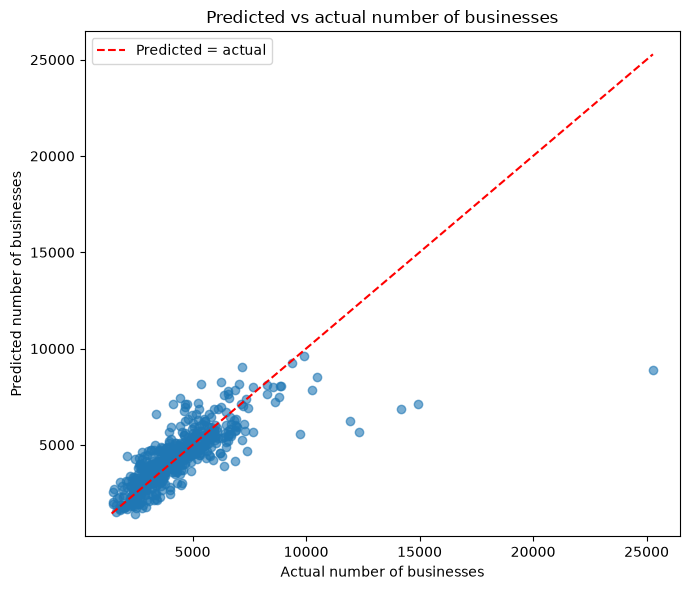

In [13]:
# Fit a linear model using all ten covariates
formula = "Businesses ~ " + " + ".join(
    col for col in BusinessData.columns if col != "Businesses"
)

model = smf.ols(formula, data=BusinessData).fit()

# Use the observations included in the fitted model
actual = model.model.endog
predicted = model.fittedvalues

# Plot predicted against actual
plt.figure(figsize=(7, 6))
plt.scatter(actual, predicted, alpha=0.6)

# Reference line: predicted = actual
lower = min(actual.min(), predicted.min())
upper = max(actual.max(), predicted.max())
plt.plot([lower, upper], [lower, upper], "r--", label="Predicted = actual")

plt.xlabel("Actual number of businesses")
plt.ylabel("Predicted number of businesses")
plt.title("Predicted vs actual number of businesses")
plt.legend()
plt.tight_layout()
plt.show()

(b) Compute the Akaike Information Criterion (AIC), Bayesian Information Criterion (BIC), and mean squared error from leave-one-out cross-validation (LOOCV) associated with this model. For AIC and BIC you may use built-in functions, but you should make clear what formula each function computes and the value of any input parameters for this dataset. [4 marks]

In [14]:
# Number of observations and estimated regression coefficients
n = int(model.nobs)
k = int(model.df_model + model.k_constant)  # Includes intercept

# AIC and BIC
aic = model.aic
bic = model.bic

# LOOCV residuals: e_i / (1 - h_ii)
residuals = np.asarray(model.resid)
leverage = model.get_influence().hat_matrix_diag
loocv_mse = np.mean((residuals / (1 - leverage))**2)

print(f"n = {n}, k = {k}")
print(f"Log-likelihood = {model.llf:.4f}")
print(f"AIC = {aic:.4f}")
print(f"BIC = {bic:.4f}")
print(f"LOOCV MSE = {loocv_mse:.4f}")

display(Math(r"\mathrm{AIC}=-2\ell+2k"))
display(Math(r"\mathrm{BIC}=-2\ell+k\ln n"))
display(Math(
    r"\mathrm{LOOCV\ MSE}"
    r"=\frac{1}{n}\sum_{i=1}^{n}"
    r"\left(\frac{e_i}{1-h_{ii}}\right)^2"
))




n = 532, k = 11
Log-likelihood = -4554.8984
AIC = 9131.7968
BIC = 9178.8399
LOOCV MSE = 1714668.0715


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

(c) It is suggested that this model is unnecessarily complicated and that one might find a simpler model with similar performance by discarding one or more covariates. For each covariate, construct a linear model to predict the number of businesses with that covariate removed. According to AIC, do you find a better model? [4 marks]

In [8]:
covariates = [
    col for col in BusinessData.columns if col != "Businesses"
]

# Use identical observations for every model
data = BusinessData.dropna(subset=["Businesses"] + covariates)

full_formula = "Businesses ~ " + " + ".join(covariates)
full_model = smf.ols(full_formula, data=data).fit()

results = [{
    "Removed covariate": "None (full model)",
    "AIC": full_model.aic,
    "Change from full": 0
}]

for removed in covariates:
    remaining = [col for col in covariates if col != removed]
    formula = "Businesses ~ " + " + ".join(remaining)

    reduced_model = smf.ols(formula, data=data).fit()

    results.append({
        "Removed covariate": removed,
        "AIC": reduced_model.aic,
        "Change from full": reduced_model.aic - full_model.aic
    })

aic_table = pd.DataFrame(results).sort_values("AIC").reset_index(drop=True)
print(aic_table.to_string(index=False))

best = aic_table.iloc[0]
print(f"\nLowest AIC: {best['AIC']:.4f}")
print(f"Removed covariate: {best['Removed covariate']}")

      Removed covariate         AIC  Change from full
         Employment_dep 9131.109299         -0.687494
      None (full model) 9131.796793          0.000000
            Pop16_64Age 9132.262814          0.466021
          Education_dep 9134.144938          2.348144
  LivingEnvironment_dep 9134.604038          2.807245
             Health_dep 9135.493605          3.696812
   Prop_born_in_UK_2011 9136.886511          5.089717
             Pop0_15Age 9143.880873         12.084080
       Median_wage_2017 9152.210129         20.413335
prop_village_or_smaller 9158.128183         26.331390
    TotalPopulation2011 9212.043566         80.246773

Lowest AIC: 9131.1093
Removed covariate: Employment_dep


(d) Starting from the best model with nine covariates, repeat the procedure in part (c), each time removing the single covariate that leads to a model producing the best available AIC for a model of that size. Continue down to the intercept-only model so that you can examine the complete sequence of nested models. (This method is known as *greedy backward stepwise selection*. In a conventional early-stopping implementation, one would stop as soon as no deletion improved AIC.) Plot AIC as a function of the number of covariates included. Which model do you recommend overall? [6 marks]

(e) Repeat parts (c) and (d) using BIC and LOOCV instead of AIC. Compare the three methods. [4 marks]

 Number of covariates                 Removed         AIC
                   10                    None 9131.796793
                    9          Employment_dep 9131.109299
                    8             Pop16_64Age 9130.623571
                    7           Education_dep 9131.450421
                    6   LivingEnvironment_dep 9134.911090
                    5              Health_dep 9140.875728
                    4    Prop_born_in_UK_2011 9170.139910
                    3              Pop0_15Age 9191.998886
                    2 prop_village_or_smaller 9247.103956
                    1     TotalPopulation2011 9393.520905
                    0        Median_wage_2017 9582.063024


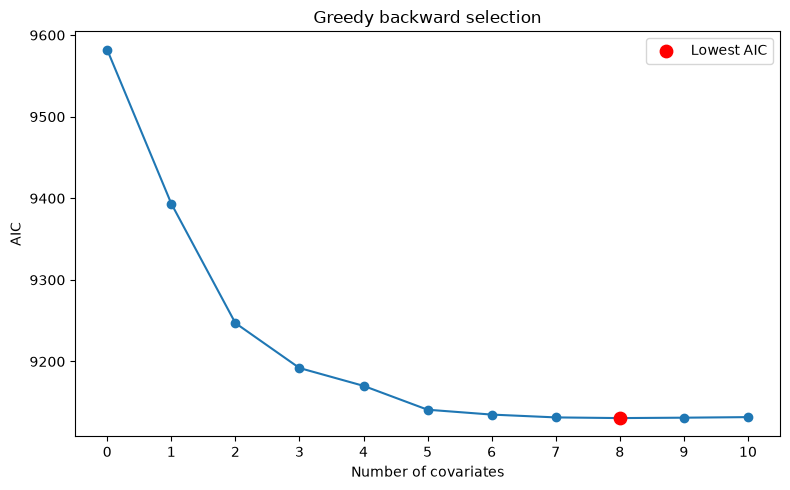


Recommended number of covariates: 8
AIC: 9130.6236
Recommended formula:
Businesses ~ TotalPopulation2011 + prop_village_or_smaller + Median_wage_2017 + Pop0_15Age + Prop_born_in_UK_2011 + Health_dep + LivingEnvironment_dep + Education_dep


In [9]:
def fit_model(variables):
    formula = (
        "Businesses ~ " + " + ".join(variables)
        if variables else "Businesses ~ 1"
    )
    return smf.ols(formula, data=data).fit()

remaining = covariates.copy()
current_model = fit_model(remaining)

results = [{
    "Number of covariates": len(remaining),
    "Removed": "None",
    "AIC": current_model.aic,
    "Variables": remaining.copy()
}]

while remaining:
    candidates = []

    # Try deleting each remaining covariate
    for removed in remaining:
        variables = [v for v in remaining if v != removed]
        fitted = fit_model(variables)
        candidates.append((fitted.aic, removed, variables))

    # Choose the deletion giving the lowest AIC at this step
    best_aic, removed, remaining = min(
        candidates, key=lambda candidate: candidate[0]
    )

    results.append({
        "Number of covariates": len(remaining),
        "Removed": removed,
        "AIC": best_aic,
        "Variables": remaining.copy()
    })

selection = pd.DataFrame(results)

print(selection[
    ["Number of covariates", "Removed", "AIC"]
].to_string(index=False))

# Best model across the complete path, including the full model
best = selection.loc[selection["AIC"].idxmin()]

plt.figure(figsize=(8, 5))
plt.plot(selection["Number of covariates"], selection["AIC"], "o-")
plt.scatter(
    best["Number of covariates"], best["AIC"],
    color="red", s=80, zorder=3, label="Lowest AIC"
)
plt.xticks(range(len(covariates) + 1))
plt.xlabel("Number of covariates")
plt.ylabel("AIC")
plt.title("Greedy backward selection")
plt.legend()
plt.tight_layout()
plt.show()

print(f"\nRecommended number of covariates: {best['Number of covariates']}")
print(f"AIC: {best['AIC']:.4f}")
print("Recommended formula:")
print(
    "Businesses ~ " + " + ".join(best["Variables"])
    if best["Variables"] else "Businesses ~ 1"
)


AIC
 Number                 Removed       Score
     10                    None 9131.796793
      9          Employment_dep 9131.109299
      8             Pop16_64Age 9130.623571
      7           Education_dep 9131.450421
      6   LivingEnvironment_dep 9134.911090
      5              Health_dep 9140.875728
      4    Prop_born_in_UK_2011 9170.139910
      3              Pop0_15Age 9191.998886
      2 prop_village_or_smaller 9247.103956
      1     TotalPopulation2011 9393.520905
      0        Median_wage_2017 9582.063024

BIC
 Number                 Removed       Score
     10                    None 9178.839872
      9          Employment_dep 9173.875734
      8             Pop16_64Age 9169.113362
      7           Education_dep 9165.663569
      6   LivingEnvironment_dep 9164.847595
      5              Health_dep 9166.535589
      4    Prop_born_in_UK_2011 9191.523127
      3              Pop0_15Age 9209.105460
      2 prop_village_or_smaller 9259.933887
      1     TotalPopul

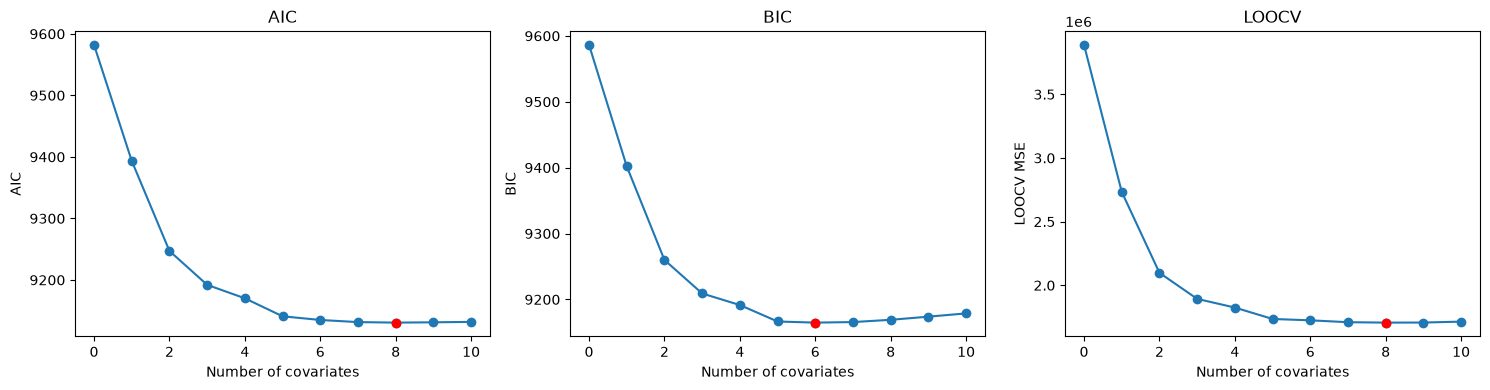

Method  Selected number                                                                                                                                 Selected variables
   AIC                8 TotalPopulation2011, prop_village_or_smaller, Median_wage_2017, Pop0_15Age, Prop_born_in_UK_2011, Health_dep, LivingEnvironment_dep, Education_dep
   BIC                6                                       TotalPopulation2011, prop_village_or_smaller, Median_wage_2017, Pop0_15Age, Prop_born_in_UK_2011, Health_dep
 LOOCV                8 TotalPopulation2011, prop_village_or_smaller, Median_wage_2017, Pop0_15Age, Prop_born_in_UK_2011, Health_dep, LivingEnvironment_dep, Education_dep
AIC and LOOCV select the same number of covariates 8, whereas BIC selects 6 covariates.


In [13]:
def backward_selection(criterion):
    remaining = covariates.copy()
    results = []

    def evaluate(variables):
        formula = "Businesses ~ " + (
            " + ".join(variables) if variables else "1"
        )
        fitted = smf.ols(formula, data=data).fit()

        if criterion == "AIC":
            return fitted.aic
        elif criterion == "BIC":
            return fitted.bic
        else:
            e = np.asarray(fitted.resid)
            h = fitted.get_influence().hat_matrix_diag
            return np.mean((e / (1 - h))**2)

    results.append({
        "Number": len(remaining),
        "Removed": "None",
        "Score": evaluate(remaining),
        "Variables": remaining.copy()
    })

    while remaining:
        candidates = []

        for variable in remaining:
            reduced = [v for v in remaining if v != variable]
            candidates.append((evaluate(reduced), variable, reduced))

        score, removed, remaining = min(
            candidates, key=lambda item: item[0]
        )

        results.append({
            "Number": len(remaining),
            "Removed": removed,
            "Score": score,
            "Variables": remaining.copy()
        })

    return pd.DataFrame(results)
    
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
comparison = []

for ax, method in zip(axes, ["AIC", "BIC", "LOOCV"]):
    path = backward_selection(method)

    # Complete sequence, including the best nine-covariate model
    print(f"\n{method}")
    print(path[["Number", "Removed", "Score"]].to_string(index=False))

    best = path.loc[path["Score"].idxmin()]

    ax.plot(path["Number"], path["Score"], "o-")
    ax.scatter(best["Number"], best["Score"], color="red", zorder=3)
    ax.set_xlabel("Number of covariates")
    ax.set_ylabel(method if method != "LOOCV" else "LOOCV MSE")
    ax.set_title(method)

    comparison.append({
        "Method": method,
        "Selected number": best["Number"],
        "Selected variables": ", ".join(best["Variables"]) or "Intercept only"
    })

plt.tight_layout()
plt.show()

print(pd.DataFrame(comparison).to_string(index=False))
print("AIC and LOOCV select the same number of covariates 8, whereas BIC selects 6 covariates.")

(f) The plot of mean square error produced by LOOCV against the number of covariates can be regarded as a direct approximation to the test error of each model. Add the empirical *training* error to your plot. Comment on your results in the context of under- and over-fitting. [4 marks]

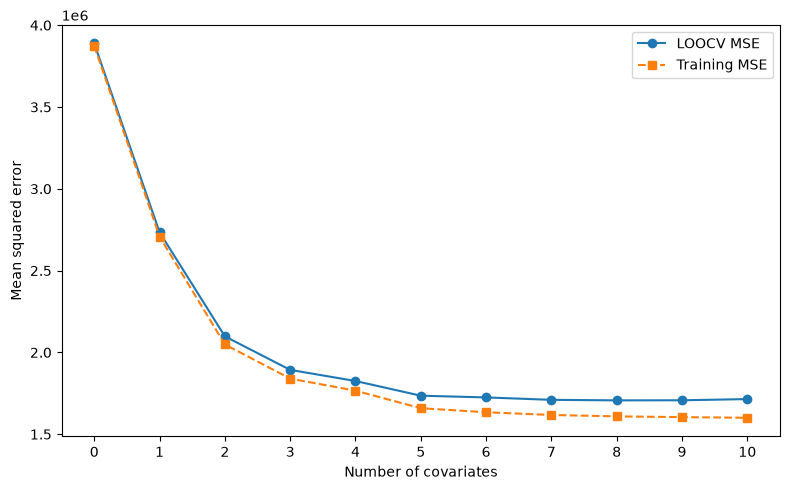

In [14]:
path = backward_selection("LOOCV")
training_mse = []

for variables in path["Variables"]:
    formula = "Businesses ~ " + (
        " + ".join(variables) if variables else "1"
    )
    fitted = smf.ols(formula, data=data).fit()
    training_mse.append(np.mean(np.asarray(fitted.resid)**2))

path["Training MSE"] = training_mse
path = path.sort_values("Number")

plt.figure(figsize=(8, 5))
plt.plot(path["Number"], path["Score"], "o-", label="LOOCV MSE")
plt.plot(path["Number"], path["Training MSE"], "s--",
         label="Training MSE")
plt.xlabel("Number of covariates")
plt.ylabel("Mean squared error")
plt.xticks(range(len(covariates) + 1))
plt.legend()
plt.tight_layout()
plt.show()


Models with very few covariates appear to underfit, as both training and LOOCV MSE are high. Both errors decrease substantially as covariates are added, with diminishing improvements beyond about five covariates. For larger models, training MSE continues to decrease, while LOOCV MSE levels off and rises slightly at ten covariates. This suggests mild overfitting in the full model, although the differences among the larger models are small. The model achieving the minimum LOOCV MSE is preferred for prediction along this selection path.